# 2. Figures — `001MoDe_R1`

This notebook reproduces the expected figures for the provided recording.
Reading functions are in `src/io_mouse.py`, plotting functions in `src/plots.py`.

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle
import os

# interactive plots
%matplotlib widget

# if the working directory is notebooks/, move to the project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")
print("Working directory:", os.getcwd())

from src import io_mouse as mm
from src import plots as pl

DATA_FILE   = "data/001MoDe_R1.csv"
MARKER_FILE = "data/001MoDe_R1.marker.csv"

Working directory: c:\Users\pigea\OneDrive\Documents\STAPS\M1\IEAP-Projects\Python-R-Git\Circular-task-analysis


## Loading the data

Coordinates are centered on the target and `y` is flipped (the screen y axis points down).
Each record is the time window between a `DoRecord` marker and the next `DoPause` marker.

In [2]:
header = mm.read_header(DATA_FILE)
data = mm.read_data(DATA_FILE, header)
markers, ref_table = mm.read_markers(MARKER_FILE)
records = mm.get_records(markers)

## Raw time series

Horizontal (`x`, blue) and vertical (`y`, orange) positions during the 5 records.
Black dashed lines mark the start of each record, red dashed lines the end.

Moving along a circle gives `x = R cos(θ)` and `y = R sin(θ)`: both positions oscillate like sine waves shifted
by a quarter of a period, one oscillation per lap. The large deviation at the beginning of most records is the movement
from the starting position to the track. Nothing is plotted between records: this version of the software does not
record during the *Pause* phases.

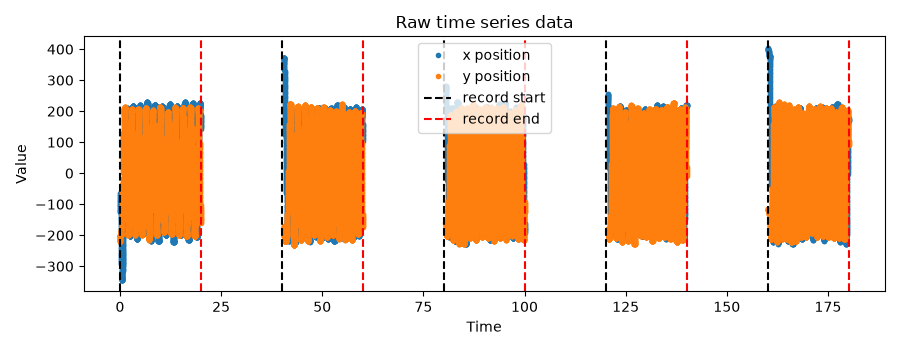

In [3]:
pl.plot_raw_time_series(data, records)

## Raw trajectory

Cursor path for all records (blue), samples inside the target (green) and limits of the target (red).

The limits are 186 and 233 pixels, not 170 and 250: MouseReMoCo considers the cursor *inside* when its **center**
is far enough from both circles. The cursor radius is 16 pixels and the external border is 1 pixel, so the inside zone goes
from `internalRadius + cursorRadius = 186` to `externalRadius - cursorRadius - borderRadius = 233`.
Each record is plotted as a separate line, otherwise the end of a record would be joined to the start of the next one.

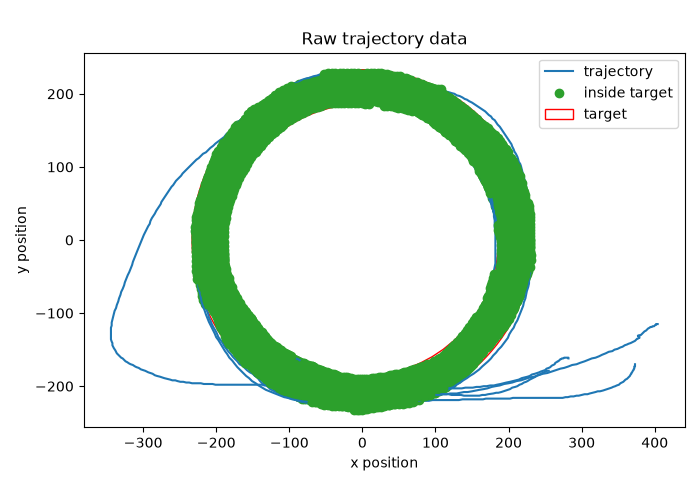

In [4]:
pl.plot_raw_trajectory(data, records, header)

## Records summary

Number of samples, time range, duration and mean sampling rate (`(n - 1) / duration`) of each record.
The sampling rate is about 199 Hz and is not constant: the operating system only sends a sample when the mouse moves.

In [5]:
pl.print_record_summary(data, records)

Number of records: 5
record 0: 3971 samples from   0.022 to  20.004 s, (19.982s, 198.679 Hz)
record 1: 3898 samples from  40.429 to  60.018 s, (19.589s, 198.938 Hz)
record 2: 3898 samples from  80.371 to 100.050 s, (19.679s, 198.028 Hz)
record 3: 3884 samples from 120.608 to 140.069 s, (19.461s, 199.527 Hz)
record 4: 3936 samples from 160.146 to 180.098 s, (19.952s, 197.223 Hz)
